<a href="https://colab.research.google.com/github/equipe31ccpj/Modelagem-Linear-GlobalSolutionCitizenAssist/blob/main/SeniorWatt_MLAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MLAM — Análise Estatística e Preditiva (CitizenTech)

**Projeto:** [SeniorWatt — Assistente Inteligente de Consumo Energético]  
**Tema:** Investigação do Consumo Energético Residencial na Terceira Idade  

### Integrantes do Grupo
* **Pedro Henrique Neves** — RM: `[571382]`
* **Akin Alexandre Mendes Martins** — RM: `[572773]`
* **Maria Eduarda Rocha Benjamim** — RM: `[570554]`

---

### Contextualização e Base de Dados
* **Fonte:** Dataset público *Household Energy Consumption* (Kaggle — 90.000 registros de 2025).
* **Recorte Amostral:** Filtrados **30.437 registros** de residências com **1 a 2 moradores** (`Household_Size <= 2`), representando o perfil domiciliar típico da terceira idade.
* **Objetivo:** Aplicar distribuição normal, testes de hipóteses e modelos de regressão linear e logística para fundamentar as recomendações do assistente digital voltado ao público sênior.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# 1. Carregamento da base de dados (Mesmo dataset de SERS - Kaggle)
df = pd.read_csv('/content/household_energy_consumption.csv')

# Recorte para residências de 1 a 2 moradores (perfil terceira idade)
df_analise = df[df['Household_Size'] <= 2].copy()


In [3]:
# === ITEM 02: DISTRIBUIÇÃO NORMAL DE PROBABILIDADE  ===
# Variável aleatória escolhida: Consumo Diário de Energia (Energy_Consumption_kWh)
var_x = df_analise['Energy_Consumption_kWh']
media_x = var_x.mean()
mediana_x = var_x.median()
desvio_x = var_x.std(ddof=0) # Desvio padrão populacional

# a) Probabilidade de X < média: P(X < media)
prob_menor_media = stats.norm.cdf(media_x, loc=media_x, scale=desvio_x)

# b) Probabilidade de X > mediana: P(X > mediana) = 1 - P(X <= mediana)
prob_maior_mediana = 1 - stats.norm.cdf(mediana_x, loc=media_x, scale=desvio_x)

def classificar_evento(p):
    if p == 0: return "Evento Impossível"
    elif p < 0.5: return "Evento Pouco Provável (< 50%)"
    elif np.isclose(p, 0.5, atol=0.02): return "Evento Igualmente Provável (~50%)"
    elif p < 1.0: return "Evento Muito Provável (> 50%)"
    else: return "Evento Certo"

print("=== ITEM 02: DISTRIBUIÇÃO NORMAL DE PROBABILIDADE ===")
print(f"Média: {media_x:.2f} kWh | Mediana: {mediana_x:.2f} kWh | Desvio Padrão: {desvio_x:.2f} kWh\n")
print(f"a) P(X < Média [{media_x:.2f}]): {prob_menor_media:.4f} ({prob_menor_media*100:.2f}%)")
print(f"   Classificação: {classificar_evento(prob_menor_media)}\n")
print(f"b) P(X > Mediana [{mediana_x:.2f}]): {prob_maior_mediana:.4f} ({prob_maior_mediana*100:.2f}%)")
print(f"   Classificação: {classificar_evento(prob_maior_mediana)}")


=== ITEM 02: DISTRIBUIÇÃO NORMAL DE PROBABILIDADE ===
Média: 4.76 kWh | Mediana: 4.60 kWh | Desvio Padrão: 2.34 kWh

a) P(X < Média [4.76]): 0.5000 (50.00%)
   Classificação: Evento Igualmente Provável (~50%)

b) P(X > Mediana [4.60]): 0.5264 (52.64%)
   Classificação: Evento Muito Provável (> 50%)


## 03. Testes de Hipóteses para a Média
Realização de dois testes de hipóteses unilaterais utilizando os parâmetros populacionais de referência (\(\mu_0 = 4,76\text{ kWh}\) e \(\sigma_0 = 2,34\text{ kWh}\)):
* **Teste A:** Unilateral à esquerda (\(H_1: \mu < \mu_0\)), com amostra \(n = 20\) e nível de significância \(\alpha = 6\%\).
* **Teste B:** Unilateral à direita (\(H_1: \mu > \mu_0\)), com amostra \(n = 25\) e nível de significância \(\alpha = 9\%\).


In [4]:
# === ITEM 03: TESTES DE HIPÓTESES PARA A MÉDIA  ===
# Parâmetros populacionais de referência (base completa filtrada)
mu_0 = media_x
sigma_0 = desvio_x

print("=== ITEM 03: TESTES DE HIPÓTESES (TESTE Z PARA A MÉDIA) ===\n")

# a) H0: mu >= mu_0 vs H1: mu < mu_0 | alpha = 6% (0.06) | n = 20
n_a = 20
alpha_a = 0.06
amostra_a = var_x.sample(n=n_a, random_state=42)
media_amostral_a = amostra_a.mean()

z_calc_a = (media_amostral_a - mu_0) / (sigma_0 / np.sqrt(n_a))
z_crit_a = stats.norm.ppf(alpha_a) # Teste unilateral à esquerda
p_valor_a = stats.norm.cdf(z_calc_a)

print(f"--- Teste A (Unilateral à Esquerda | n={n_a}, alpha={alpha_a*100:.0f}%) ---")
print(f"Média Populacional (mu_0): {mu_0:.2f} | Média Amostral: {media_amostral_a:.2f}")
print(f"Z calculado: {z_calc_a:.4f} | Z crítico: {z_crit_a:.4f} | p-valor: {p_valor_a:.4f}")
if z_calc_a < z_crit_a:
    print("Decisão: Rejeita H0 (Há evidência de que a média amostral é menor que a populacional).\n")
else:
    print("Decisão: Não rejeita H0 (Não há evidência suficiente de que a média amostral seja menor).\n")

# b) H0: mu <= mu_0 vs H1: mu > mu_0 | alpha = 9% (0.09) | n = 25
n_b = 25
alpha_b = 0.09
amostra_b = var_x.sample(n=n_b, random_state=10)
media_amostral_b = amostra_b.mean()

z_calc_b = (media_amostral_b - mu_0) / (sigma_0 / np.sqrt(n_b))
z_crit_b = stats.norm.ppf(1 - alpha_b) # Teste unilateral à direita
p_valor_b = 1 - stats.norm.cdf(z_calc_b)

print(f"--- Teste B (Unilateral à Direita | n={n_b}, alpha={alpha_b*100:.0f}%) ---")
print(f"Média Populacional (mu_0): {mu_0:.2f} | Média Amostral: {media_amostral_b:.2f}")
print(f"Z calculado: {z_calc_b:.4f} | Z crítico: {z_crit_b:.4f} | p-valor: {p_valor_b:.4f}")
if z_calc_b > z_crit_b:
    print("Decisão: Rejeita H0 (Há evidência de que a média amostral é maior que a populacional).")
else:
    print("Decisão: Não rejeita H0 (Não há evidência suficiente de que a média amostral seja maior).")


=== ITEM 03: TESTES DE HIPÓTESES (TESTE Z PARA A MÉDIA) ===

--- Teste A (Unilateral à Esquerda | n=20, alpha=6%) ---
Média Populacional (mu_0): 4.76 | Média Amostral: 3.45
Z calculado: -2.5023 | Z crítico: -1.5548 | p-valor: 0.0062
Decisão: Rejeita H0 (Há evidência de que a média amostral é menor que a populacional).

--- Teste B (Unilateral à Direita | n=25, alpha=9%) ---
Média Populacional (mu_0): 4.76 | Média Amostral: 5.31
Z calculado: 1.1807 | Z crítico: 1.3408 | p-valor: 0.1189
Decisão: Não rejeita H0 (Não há evidência suficiente de que a média amostral seja maior).


## 04. Análise Bivariada e Regressão Linear Simples
Investigação da relação linear entre o **Consumo no Horário de Pico (`Peak_Hours_Usage_kWh`)** e o **Consumo Total Diário (`Energy_Consumption_kWh`)**, incluindo covariância, correlação de Pearson, ajuste da reta de regressão, avaliação via \(R^2\) e Teste \(F\), e previsão de consumo.


In [5]:
# === ITEM 04: ANÁLISE BIVARIADA (2,0 pontos) ===
X_biv = df_analise['Peak_Hours_Usage_kWh']
Y_biv = df_analise['Energy_Consumption_kWh']

# b) Covariância e Correlação Linear de Pearson
cov_xy = np.cov(X_biv, Y_biv)[0, 1]
corr_xy, _ = stats.pearsonr(X_biv, Y_biv)

# d) e e) Modelo de Regressão Linear Simples via Statsmodels
X_biv_sm = sm.add_constant(X_biv)
modelo_simples = sm.OLS(Y_biv, X_biv_sm).fit()
b0, b1 = modelo_simples.params['const'], modelo_simples.params['Peak_Hours_Usage_kWh']

print("=== ITEM 04: ANÁLISE BIVARIADA E REGRESSÃO LINEAR SIMPLES ===")
print(f"b) Covariância: {cov_xy:.4f} | Correlação de Pearson (r): {corr_xy:.4f}")
print(f"d) Equação da Reta: Consumo_Total = {b0:.4f} + {b1:.4f} * Consumo_Pico")
print(f"e) Adequação do Modelo -> R²: {modelo_simples.rsquared:.4f} | Estatística F: {modelo_simples.fvalue:.2f} (p-valor F: {modelo_simples.f_pvalue:.4e})")

# f) Previsão
pico_teste = 2.5
previsao_biv = b0 + b1 * pico_teste
print(f"f) Previsão para Consumo no Pico = {pico_teste} kWh -> Consumo Total Estimado: {previsao_biv:.2f} kWh/dia")

# Amostra de 1.500 pontos para visualização limpa nos gráficos
amostra_plot = df_analise.sample(1500, random_state=42)


=== ITEM 04: ANÁLISE BIVARIADA E REGRESSÃO LINEAR SIMPLES ===
b) Covariância: 2.4713 | Correlação de Pearson (r): 0.9665
d) Equação da Reta: Consumo_Total = 0.7159 + 2.0724 * Consumo_Pico
e) Adequação do Modelo -> R²: 0.9342 | Estatística F: 431941.25 (p-valor F: 0.0000e+00)
f) Previsão para Consumo no Pico = 2.5 kWh -> Consumo Total Estimado: 5.90 kWh/dia


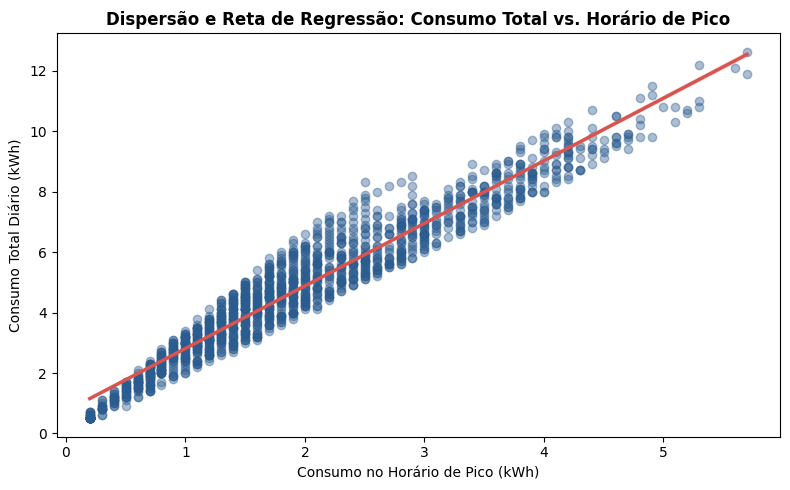

In [6]:
# Gráfico 1 (Item 04): Dispersão + Reta de Regressão
plt.figure(figsize=(8, 5))
sns.regplot(
    data=amostra_plot,
    x='Peak_Hours_Usage_kWh',
    y='Energy_Consumption_kWh',
    scatter_kws={'alpha': 0.4, 'color': '#2b5c8f'},
    line_kws={'color': '#d9534f', 'linewidth': 2.5}
)
plt.title('Dispersão e Reta de Regressão: Consumo Total vs. Horário de Pico', fontweight='bold')
plt.xlabel('Consumo no Horário de Pico (kWh)')
plt.ylabel('Consumo Total Diário (kWh)')
plt.tight_layout()
plt.show()


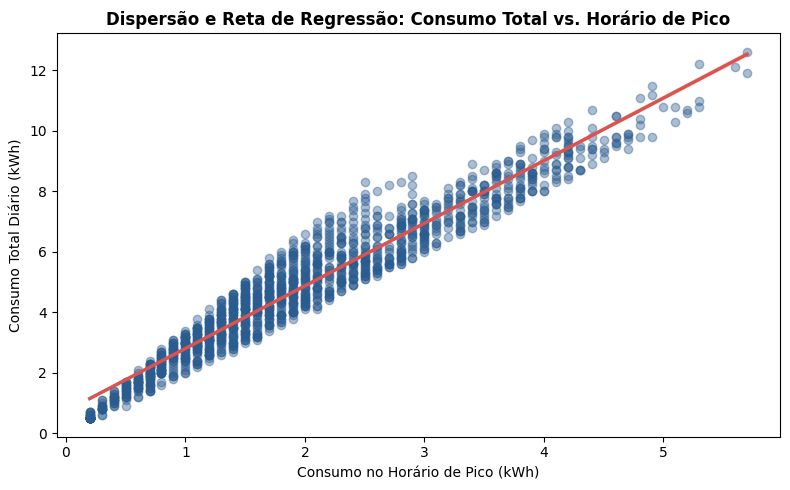

In [7]:
# Gráfico 1 (Item 04): Dispersão + Reta de Regressão
plt.figure(figsize=(8, 5))
sns.regplot(
    data=amostra_plot,
    x='Peak_Hours_Usage_kWh',
    y='Energy_Consumption_kWh',
    scatter_kws={'alpha': 0.4, 'color': '#2b5c8f'},
    line_kws={'color': '#d9534f', 'linewidth': 2.5}
)
plt.title('Dispersão e Reta de Regressão: Consumo Total vs. Horário de Pico', fontweight='bold')
plt.xlabel('Consumo no Horário de Pico (kWh)')
plt.ylabel('Consumo Total Diário (kWh)')
plt.tight_layout()
plt.show()


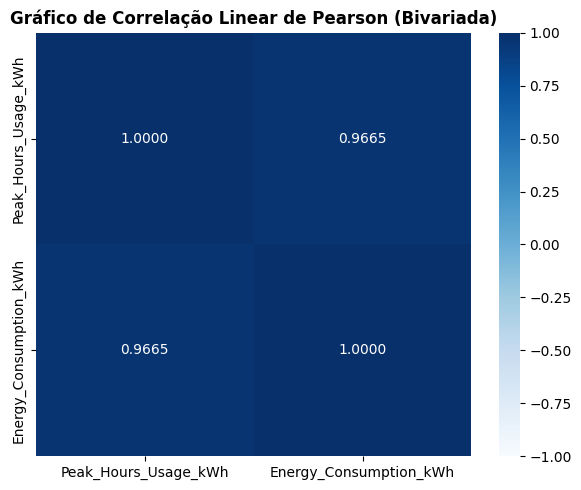

In [8]:
# Gráfico 2 (Item 04): Correlação Linear de Pearson (Heatmap)
plt.figure(figsize=(6, 5))
corr_matrix_biv = df_analise[['Peak_Hours_Usage_kWh', 'Energy_Consumption_kWh']].corr()
sns.heatmap(corr_matrix_biv, annot=True, cmap='Blues', vmin=-1, vmax=1, fmt='.4f')
plt.title('Gráfico de Correlação Linear de Pearson (Bivariada)', fontweight='bold')
plt.tight_layout()
plt.show()


## 05. Análise Multivariada e Regressão Linear Múltipla
Modelagem do **Consumo Total Diário** a partir de duas variáveis explicativas quantitativas: **Consumo no Horário de Pico** e **Temperatura Média Ambiente (`Avg_Temperature_C`)**, analisando as matrizes de covariância e correlação, equação múltipla, \(R^2\), Teste \(F\) e previsão.


In [9]:
# === ITEM 05: REGRESSÃO LINEAR MÚLTIPLA (2,0 pontos) ===
cols_mult = ['Peak_Hours_Usage_kWh', 'Avg_Temperature_C', 'Energy_Consumption_kWh']
df_mult = df_analise[cols_mult]

# b) Matriz de Covariância e Matriz de Correlação de Pearson
print("=== ITEM 05: ANÁLISE MULTIVARIADA E REGRESSÃO LINEAR MÚLTIPLA ===")
print("b) Matriz de Covariância:")
display(df_mult.cov().round(4))
print("\nMatriz de Correlação de Pearson:")
display(df_mult.corr().round(4))

# d) e e) Ajuste da Regressão Linear Múltipla
X_mult = sm.add_constant(df_analise[['Peak_Hours_Usage_kWh', 'Avg_Temperature_C']])
Y_mult = df_analise['Energy_Consumption_kWh']
modelo_multiplo = sm.OLS(Y_mult, X_mult).fit()

c0 = modelo_multiplo.params['const']
c1 = modelo_multiplo.params['Peak_Hours_Usage_kWh']
c2 = modelo_multiplo.params['Avg_Temperature_C']

print(f"\nd) Equação da Regressão Múltipla: Consumo_Total = {c0:.4f} + ({c1:.4f} * Consumo_Pico) + ({c2:.4f} * Temperatura)")
print(f"e) Adequação do Modelo -> R²: {modelo_multiplo.rsquared:.4f} | R² Ajustado: {modelo_multiplo.rsquared_adj:.4f} | Teste F: {modelo_multiplo.fvalue:.2f} (p-valor: {modelo_multiplo.f_pvalue:.4e})")

# f) Previsão utilizando 2 variáveis explicativas
prev_mult = c0 + c1 * 2.5 + c2 * 24.0
print(f"f) Previsão (Pico = 2.5 kWh e Temp = 24°C) -> Consumo Total Estimado: {prev_mult:.2f} kWh/dia")


=== ITEM 05: ANÁLISE MULTIVARIADA E REGRESSÃO LINEAR MÚLTIPLA ===
b) Matriz de Covariância:


,Peak_Hours_Usage_kWh,Avg_Temperature_C,Energy_Consumption_kWh
Peak_Hours_Usage_kWh,1.1925,0.2568,2.4713
Avg_Temperature_C,0.2568,6.2231,0.5700
Energy_Consumption_kWh,2.4713,0.5700,5.4825



Matriz de Correlação de Pearson:


,Peak_Hours_Usage_kWh,Avg_Temperature_C,Energy_Consumption_kWh
Peak_Hours_Usage_kWh,1.0000,0.0943,0.9665
Avg_Temperature_C,0.0943,1.0000,0.0976
Energy_Consumption_kWh,0.9665,0.0976,1.0000



d) Equação da Regressão Múltipla: Consumo_Total = 0.6111 + (2.0711 * Consumo_Pico) + (0.0061 * Temperatura)
e) Adequação do Modelo -> R²: 0.9342 | R² Ajustado: 0.9342 | Teste F: 216112.30 (p-valor: 0.0000e+00)
f) Previsão (Pico = 2.5 kWh e Temp = 24°C) -> Consumo Total Estimado: 5.94 kWh/dia


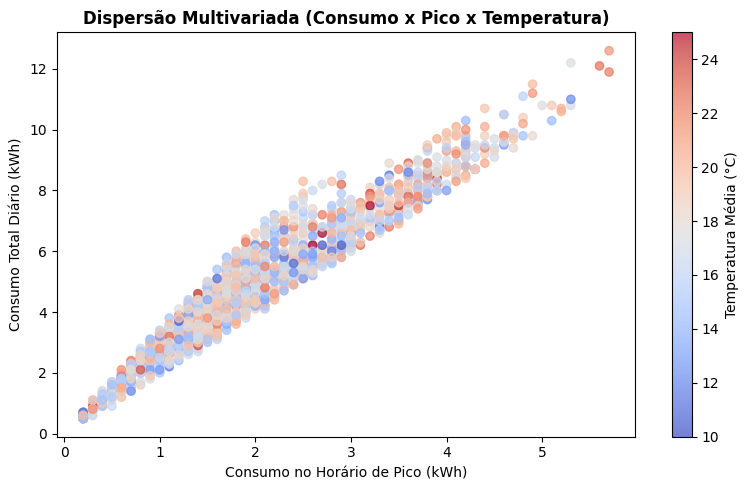

In [10]:
# Gráfico 1 (Item 05): Dispersão Multivariada
plt.figure(figsize=(8, 5))
sc = plt.scatter(
    amostra_plot['Peak_Hours_Usage_kWh'],
    amostra_plot['Energy_Consumption_kWh'],
    c=amostra_plot['Avg_Temperature_C'],
    cmap='coolwarm',
    alpha=0.7
)
plt.colorbar(sc, label='Temperatura Média (°C)')
plt.title('Dispersão Multivariada (Consumo x Pico x Temperatura)', fontweight='bold')
plt.xlabel('Consumo no Horário de Pico (kWh)')
plt.ylabel('Consumo Total Diário (kWh)')
plt.tight_layout()
plt.show()


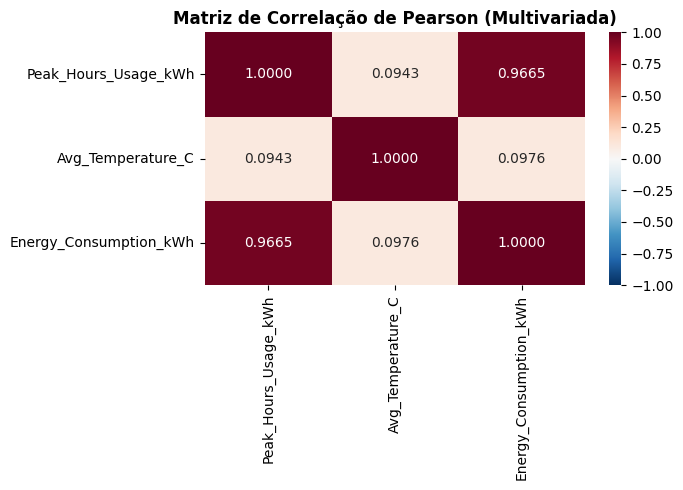

In [11]:
# Gráfico 2 (Item 05): Heatmap de Correlação
plt.figure(figsize=(7, 5))
sns.heatmap(df_mult.corr(), annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt='.4f')
plt.title('Matriz de Correlação de Pearson (Multivariada)', fontweight='bold')
plt.tight_layout()
plt.show()


## 06. Regressão Logística Binária
Classificação binária da presença de **Ar-Condicionado (`Has_AC`: 1 = Sim, 0 = Não)** utilizando o Consumo Total, o Consumo no Pico e a Temperatura Média, com avaliação da matriz de confusão, acurácia e previsão probabilística para um novo caso.


In [12]:
# === ITEM 06: REGRESSÃO LOGÍSTICA BINÁRIA (2,0 pontos) ===
df_analise['AC_Binario'] = (df_analise['Has_AC'] == 'Yes').astype(int)

features_log = ['Energy_Consumption_kWh', 'Peak_Hours_Usage_kWh', 'Avg_Temperature_C']
X_log = df_analise[features_log]
Y_log = df_analise['AC_Binario']

# Treinamento do modelo logístico
clf_log = LogisticRegression(random_state=42)
clf_log.fit(X_log, Y_log)

# a) Equação da Regressão Logística Binária
b0_log = clf_log.intercept_[0]
coefs = clf_log.coef_[0]

print("=== ITEM 06: REGRESSÃO LOGÍSTICA BINÁRIA ===")
print("a) Equação do Logit (z):")
print(f"   z = {b0_log:.4f} + ({coefs[0]:.4f} * Consumo_Total) + ({coefs[1]:.4f} * Consumo_Pico) + ({coefs[2]:.4f} * Temperatura)")
print("   Probabilidade P(Has_AC = 1) = 1 / (1 + e^(-z))\n")

# b) Matriz de Confusão e Acurácia
Y_pred = clf_log.predict(X_log)
matriz_conf = confusion_matrix(Y_log, Y_pred)
acuracia = accuracy_score(Y_log, Y_pred)

print(f"b) Acurácia do Modelo: {acuracia*100:.2f}%")
print("Matriz de Confusão:")
print(matriz_conf)

# c) Classificação de Novo Caso
novo_caso = pd.DataFrame([[7.5, 3.0, 22.0]], columns=features_log)
classe_prevista = clf_log.predict(novo_caso)[0]
prob_prevista = clf_log.predict_proba(novo_caso)[0][1]

print(f"\nc) Classificação de Novo Caso (Consumo=7.5 kWh, Pico=3.0 kWh, Temp=22°C):")
print(f"   Probabilidade de ter Ar-Condicionado: {prob_prevista*100:.2f}% -> Classificação: {'Possui AC (1)' if classe_prevista == 1 else 'Não Possui AC (0)'}")


=== ITEM 06: REGRESSÃO LOGÍSTICA BINÁRIA ===
a) Equação do Logit (z):
   z = -0.7714 + (-12.6807 * Consumo_Total) + (32.6300 * Consumo_Pico) + (-0.0568 * Temperatura)
   Probabilidade P(Has_AC = 1) = 1 / (1 + e^(-z))

b) Acurácia do Modelo: 96.74%
Matriz de Confusão:
[[15163   329]
 [  664 14281]]

c) Classificação de Novo Caso (Consumo=7.5 kWh, Pico=3.0 kWh, Temp=22°C):
   Probabilidade de ter Ar-Condicionado: 68.23% -> Classificação: Possui AC (1)


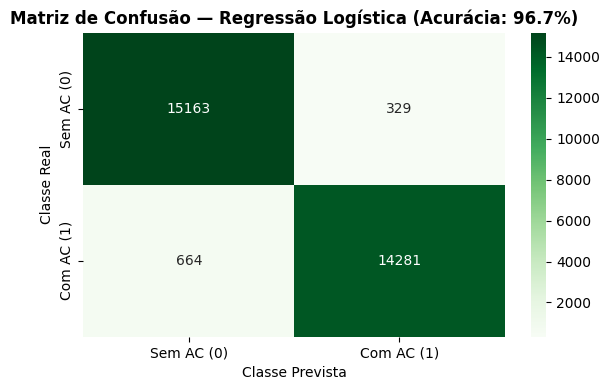

In [13]:
# Gráfico (Item 06): Matriz de Confusão
plt.figure(figsize=(6, 4))
sns.heatmap(
    matriz_conf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Sem AC (0)', 'Com AC (1)'],
    yticklabels=['Sem AC (0)', 'Com AC (1)']
)
plt.title(f'Matriz de Confusão — Regressão Logística (Acurácia: {acuracia*100:.1f}%)', fontweight='bold')
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.tight_layout()
plt.show()
